In [14]:
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt
import matplotlib as mpl
import statistics
import math
import sys
from pylab import *
from math import log
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error
from tqdm import tqdm
from generate_data import *
from train_models import *
from honest_trees import *
%matplotlib inline
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


This notebook is used to run the simulation experiments for fitting sparse linear model with continuous features. The structure of this notebook is as follows: (a) We first fit different tree-based estimators on a linear model with X generated from Uniform([0,1]^d). We then plot the generalisation performance of these different estimators. 

# Examine Generalisation performance for Sparse Linear Models 

In [15]:
def log_list(t):
    return [log(x,math.e) for x in t]

In [16]:
def get_best_fit_line(x,y):
    m, b = np.polyfit(x, y, 1)
    return [m,b]

In [ ]:
n_train = [100,200,400,800,1600,3200]   # doubling grid: index i+1 is exactly 2n
n_test = 500
d = 50
beta = 1
sigma = 0.1
sparsity = [10,20]
n_avg = 25

In [18]:
# Initialize matrix for honest CART 
honest_CART_scores = []
honest_CART_error_bar = []
honest_CART_best_fit = []
#Initialize matrix for honest CART with CCP 
#honest_CART_CCP_scores = []
#honest_CART_CCP_error_bar = []

#Initialize matrix for dishonest CART 
CART_scores = []
CART_error_bar = []
CART_best_fit = []

#Initialize Matrix for dishonest CART with CCP 
#CART_CCP_scores = []
#CART_CCP_error_bar = []

#Initialize Matrix for RF
RF_scores = []
RF_error_bar = []
RF_best_fit = []
#Initialize matrix for theoretical lower bound 


In [19]:
#This cell's code is used to fit and predict for on linear model varying across the number of training samples/sparsity 
for s in sparsity: 
    honest_CART_s = []
    honest_CART_s_error_bar = []
    
    
    
    #honest_CART_CCP_s = []
    #honest_CART_CCP_s_error_bar = []
    CART_s = []
    CART_s_error_bar = []
  
    
    #CART_CCP_s = []
    #CART_CCP_s_error_bar = []
    
    RF_s = []
    RF_s_error_bar = []

    
    for n in tqdm(n_train):
        honest_CART = []
        #honest_CART_CCP = []
        CART = []
        #CART_CCP = []
        RF = []
        for j in range(n_avg):
            #Create data to fit models 
            X_train = sample_uniform_X(n,d)
            X_honest = sample_uniform_X(n,d)
            X_test = sample_uniform_X(n_test,d)
            
            
            y_train = linear_model(X_train,s,beta,sigma)
            y_honest = linear_model(X_honest,s,beta,sigma)
            y_test = linear_model(X_test,s,beta,0) #zero noise since we want to measure ||\hat{f} - f||_2
            
            
            
            #Fit and predict for all versions of CART
            honest_CART_MSE,CART_MSE =  train_all_models(X_train,y_train,X_honest,y_honest,X_test,y_test,sigma,k = 5)
            honest_CART.append(honest_CART_MSE)
            
            
            
            #honest_CART_CCP.append(honest_CART_CCP_MSE)
            CART.append(CART_MSE)
            #CART_CCP.append(CART_CCP_MSE)
            
            #Fit and predict for RF
            rf = RandomForestRegressor(n_estimators = 100,max_features = 0.33)
            rf.fit(X_train,y_train)
            rf_preds = rf.predict(X_test)
            RF.append(mean_squared_error(y_test,rf_preds))
            
            
            
        #Store Performance in matrix
        honest_CART_s.append(statistics.mean(honest_CART))
        honest_CART_s_error_bar.append(statistics.stdev(honest_CART))
        
        #honest_CART_CCP_s.append(statistics.mean(honest_CART_CCP))
        #honest_CART_CCP_s_error_bar.append(statistics.stdev(honest_CART_CCP))
        
        CART_s.append(statistics.mean(CART))
        CART_s_error_bar.append(statistics.stdev(CART))
        
        #CART_CCP_s.append(statistics.mean(CART_CCP))
        #CART_CCP_s_error_bar.append(statistics.stdev(CART_CCP))
        
        RF_s.append(statistics.mean(RF))
        RF_s_error_bar.append(statistics.stdev(RF))
        

    
    #save results 
    honest_CART_scores.append(honest_CART_s)
    #honest_CART_CCP_scores.append(honest_CART_CCP_s)
    CART_scores.append(CART_s)
    #CART_CCP_scores.append(CART_CCP_s)
    RF_scores.append(RF_s)
    
    
    honest_CART_error_bar.append(honest_CART_s_error_bar)
    #honest_CART_CCP_error_bar.append(honest_CART_CCP_s_error_bar)
    CART_error_bar.append(CART_s_error_bar)
    #CART_CCP_error_bar.append(CART_CCP_s_error_bar) 
    RF_error_bar.append(RF_s_error_bar)


100%|██████████| 6/6 [21:53<00:00, 218.96s/it]


# Save Results 

In [20]:
honest_CART_results = (honest_CART_scores,honest_CART_error_bar)
with open('results/linear_cts_budget/honestCART.pkl','wb') as f:
    pickle.dump(honest_CART_results, f)

In [21]:
CART_results = (CART_scores,CART_error_bar)
with open('results/linear_cts_budget/CART.pkl','wb') as f:
    pickle.dump(CART_results,f)

In [22]:
RF_results = (RF_scores,RF_error_bar)
with open('results/linear_cts_budget/RF.pkl','wb') as f:
    pickle.dump(RF_results,f)

In [25]:
honest_CART_scores

[[0.822282506737631,
  0.7336539778110143,
  0.6746656142890468,
  0.6200944641156487,
  0.5411219234781349,
  0.46142121973128986],
 [1.776645295261982,
  1.7207586938714483,
  1.610996844615711,
  1.5721476926037599,
  1.468039188629186,
  1.4709667060157163]]

# Load Results 

In [33]:
with open ('results/linear_cts_budget/honestCART.pkl','rb') as f:
    honest_CART_scores1,honest_CART_error_bar1 = pickle.load(f)

In [34]:
with open ('results/linear_cts_budget/CART.pkl','rb') as f:
    CART_scores1,CART_error_bar1 = pickle.load(f)

In [35]:
with open ('results/linear_cts_budget/RF.pkl','rb') as f:
    RF_scores1,RF_error_bar1 = pickle.load(f)

[]

# Best-fit line Slopes

In [36]:
for (i,s) in enumerate(sparsity):
    honest_CART_best_fit.append(get_best_fit_line(log_list(n_train),log_list(honest_CART_scores[i])))
    CART_best_fit.append(get_best_fit_line(log_list(n_train),log_list(CART_scores[i])))
    RF_best_fit.append(get_best_fit_line(log_list(n_train),log_list(RF_scores[i])))

In [47]:
honest_CART_best_fit

[[-0.16019633812679554, 0.554602968277088],
 [-0.05956100838566489, 0.8469391818521307],
 [-0.16019633812679554, 0.554602968277088],
 [-0.05956100838566489, 0.8469391818521307]]

# Plot Results 

In [40]:
import pylab
# Set global plotting parameters
plt.style.use("fivethirtyeight")
mpl.rcParams['lines.markersize'] = 10
mpl.rcParams['grid.linewidth'] = 2.5
mpl.rcParams['legend.fontsize'] = 20
pylab.rcParams['xtick.major.pad'] = 5
pylab.rcParams['ytick.major.pad'] = 5
mpl.rcParams["figure.figsize"] = [8, 6]
mpl.rcParams['savefig.transparent'] = True
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['figure.edgecolor'] = 'black'
# plt.rcParams['patch.edgecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'
# plt.rcParams['grid.color'] = 'black'
colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

label_size = 25
mpl.rcParams['xtick.labelsize'] = label_size 
mpl.rcParams['ytick.labelsize'] = label_size 
mpl.rcParams['axes.labelsize'] = label_size
mpl.rcParams['axes.titlesize'] = label_size
mpl.rcParams['figure.titlesize'] = label_size


([<matplotlib.axis.YTick at 0x129870650>,
 [])

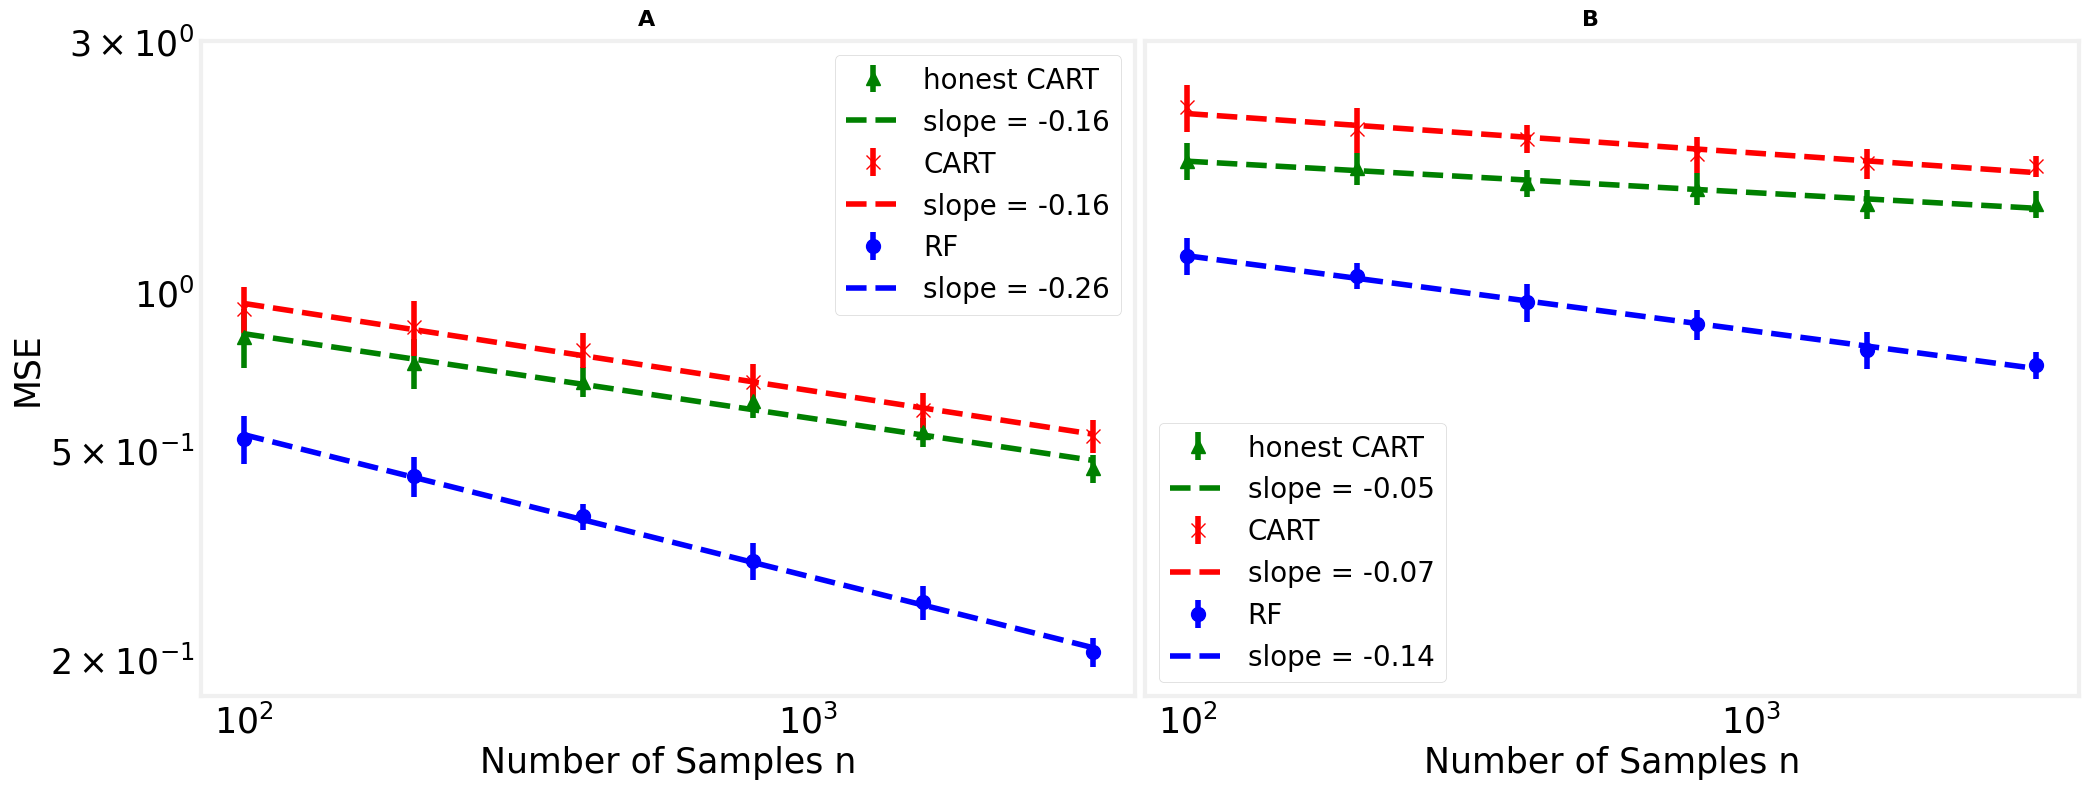

In [45]:
linear_lower_bound_fig,linear_lower_bound_axs = plt.subplots(1,2,figsize = (20,8),sharex = True,sharey = True)


#Plot Performance for different models 

# s = 10
linear_lower_bound_axs[0].errorbar(n_train,honest_CART_scores[0],yerr = honest_CART_error_bar[0],fmt = '^',label = 'honest CART',color = 'green')
linear_lower_bound_axs[0].errorbar(n_train,pow(math.e,honest_CART_best_fit[0][0]*np.array(log_list(n_train))+honest_CART_best_fit[0][1]),linestyle = 'dashed',label = 'slope = ' +str(honest_CART_best_fit[0][0])[:5],color = 'green')

linear_lower_bound_axs[0].errorbar(n_train,CART_scores[0],yerr = CART_error_bar[0],fmt = 'x',label = 'CART',color = 'red')
linear_lower_bound_axs[0].errorbar(n_train,pow(math.e,CART_best_fit[0][0]*np.array(log_list(n_train))+CART_best_fit[0][1]),linestyle = 'dashed',label = 'slope = ' + str(CART_best_fit[0][0])[:5],color = 'red')


linear_lower_bound_axs[0].errorbar(n_train,RF_scores[0],yerr = RF_error_bar[0],fmt = 'o',label = 'RF',color = 'blue')
linear_lower_bound_axs[0].errorbar(n_train,pow(math.e,RF_best_fit[0][0]*np.array(log_list(n_train))+RF_best_fit[0][1]),linestyle = 'dashed',label = 'slope = ' + str(RF_best_fit[0][0])[:5],color = 'blue')



# s = 20 
linear_lower_bound_axs[1].errorbar(n_train,honest_CART_scores[1],yerr = honest_CART_error_bar[1],fmt = '^',label = 'honest CART',color = 'green')
linear_lower_bound_axs[1].errorbar(n_train,pow(math.e,honest_CART_best_fit[1][0]*np.array(log_list(n_train))+honest_CART_best_fit[1][1]),linestyle = 'dashed',label = 'slope = ' +str(honest_CART_best_fit[1][0])[:5],color = 'green')

linear_lower_bound_axs[1].errorbar(n_train,CART_scores[1],yerr = CART_error_bar[1],fmt = 'x',label = 'CART',color = 'red')
linear_lower_bound_axs[1].errorbar(n_train,pow(math.e,CART_best_fit[1][0]*np.array(log_list(n_train))+CART_best_fit[1][1]),linestyle = 'dashed',label = 'slope = ' + str(CART_best_fit[1][0])[:5],color = 'red')


linear_lower_bound_axs[1].errorbar(n_train,RF_scores[1],yerr = RF_error_bar[1],fmt = 'o',label = 'RF',color = 'blue')
linear_lower_bound_axs[1].errorbar(n_train,pow(math.e,RF_best_fit[1][0]*np.array(log_list(n_train))+RF_best_fit[1][1]),linestyle = 'dashed',label = 'slope = ' +str(RF_best_fit[1][0])[:5],color = 'blue')


linear_lower_bound_axs[0].legend(loc = 'best')
linear_lower_bound_axs[1].legend(loc = 'best')

linear_lower_bound_axs[0].text(500.0, 3.45, 'A',
      fontsize=16, fontweight='bold', va='top')
linear_lower_bound_axs[1].text(500.0, 3.45, 'B',
      fontsize=16, fontweight='bold', va='top')
linear_lower_bound_axs[0].set_ylabel('MSE',fontsize = 25)
#linear_lower_bound_axs[1].set_ylabel('MSE',fontsize = 18)

linear_lower_bound_axs[0].set_xlabel('Number of Samples n',fontsize = 25)
linear_lower_bound_axs[1].set_xlabel('Number of Samples n',fontsize = 25)

linear_lower_bound_axs[0].set_yscale('log')
linear_lower_bound_axs[1].set_yscale('log')
linear_lower_bound_axs[0].set_xscale('log')
linear_lower_bound_axs[1].set_xscale('log')

linear_lower_bound_axs[0].grid()
linear_lower_bound_axs[1].grid()



plt.tight_layout(pad=0.4,w_pad=0.5, h_pad=1.5)

labels = [r'$2 \times \mathregular{10^{-1}}$', r'$5 \times \mathregular{10^{-1}}$', r'$\mathregular{10^{0}}$',r'$3 \times \mathregular{10^{0}}$']
ytick = [0.2,0.5,1.0,3.0]
#plt.xticks(n_train, labels, rotation='vertical')


#linear_lower_bound_axs[0].set_yticks([0.1, 0.5, 1.0,3.0])
plt.yticks(ytick,labels)
#linear_lower_bound_axs[0].get_yaxis().set_major_formatter(matplotlib.ticker.ScalarFormatter())
#linear_lower_bound_axs[0].set_ylim(0.1, 3.0);




In [11]:
linear_lower_bound_fig.savefig('figures/linear_cts_budget_matched.png')

# Budget-matched comparison

In [29]:
# Budget-matched comparison: honest CART at n  vs  non-honest CART at 2n.
# The grid doubles, so index i+1 is exactly twice index i.
ratios = {}
print(f"{'s':>3} {'n':>6} {'2n':>6} {'honest(n)':>11} {'CART(2n)':>11} {'ratio':>8} {'se':>7}")
for k, s in enumerate(sparsity):
    ns, rs, ses = [], [], []
    for i in range(len(n_train) - 1):
        h   = honest_CART_scores[k][i]
        c   = CART_scores[k][i + 1]
        seh = honest_CART_error_bar[k][i]     / math.sqrt(n_avg)
        sec = CART_error_bar[k][i + 1]        / math.sqrt(n_avg)
        r   = c / h
        se  = r * math.sqrt((seh / h) ** 2 + (sec / c) ** 2)
        ns.append(n_train[i]); rs.append(r); ses.append(se)
        print(f"{s:>3} {n_train[i]:>6} {n_train[i+1]:>6} {h:>11.4f} {c:>11.4f} {r:>8.3f} {se:>7.3f}")
    ratios[s] = (ns, rs, ses)
    print()
# ratio > 1  =>  honest CART at n beats non-honest CART at 2n, i.e. the honest
# advantage is NOT explained by the honest arm seeing more data.

  s      n     2n   honest(n)    CART(2n)    ratio      se
 10    100    200      0.8223      0.8580    1.043   0.037
 10    200    400      0.7337      0.7748    1.056   0.028
 10    400    800      0.6747      0.6747    1.000   0.021
 10    800   1600      0.6201      0.5972    0.963   0.021
 10   1600   3200      0.5411      0.5324    0.984   0.019

 20    100    200      1.7766      2.0403    1.148   0.029
 20    200    400      1.7208      1.9575    1.138   0.021
 20    400    800      1.6110      1.8264    1.134   0.023
 20    800   1600      1.5721      1.7560    1.117   0.021
 20   1600   3200      1.4680      1.7355    1.182   0.019



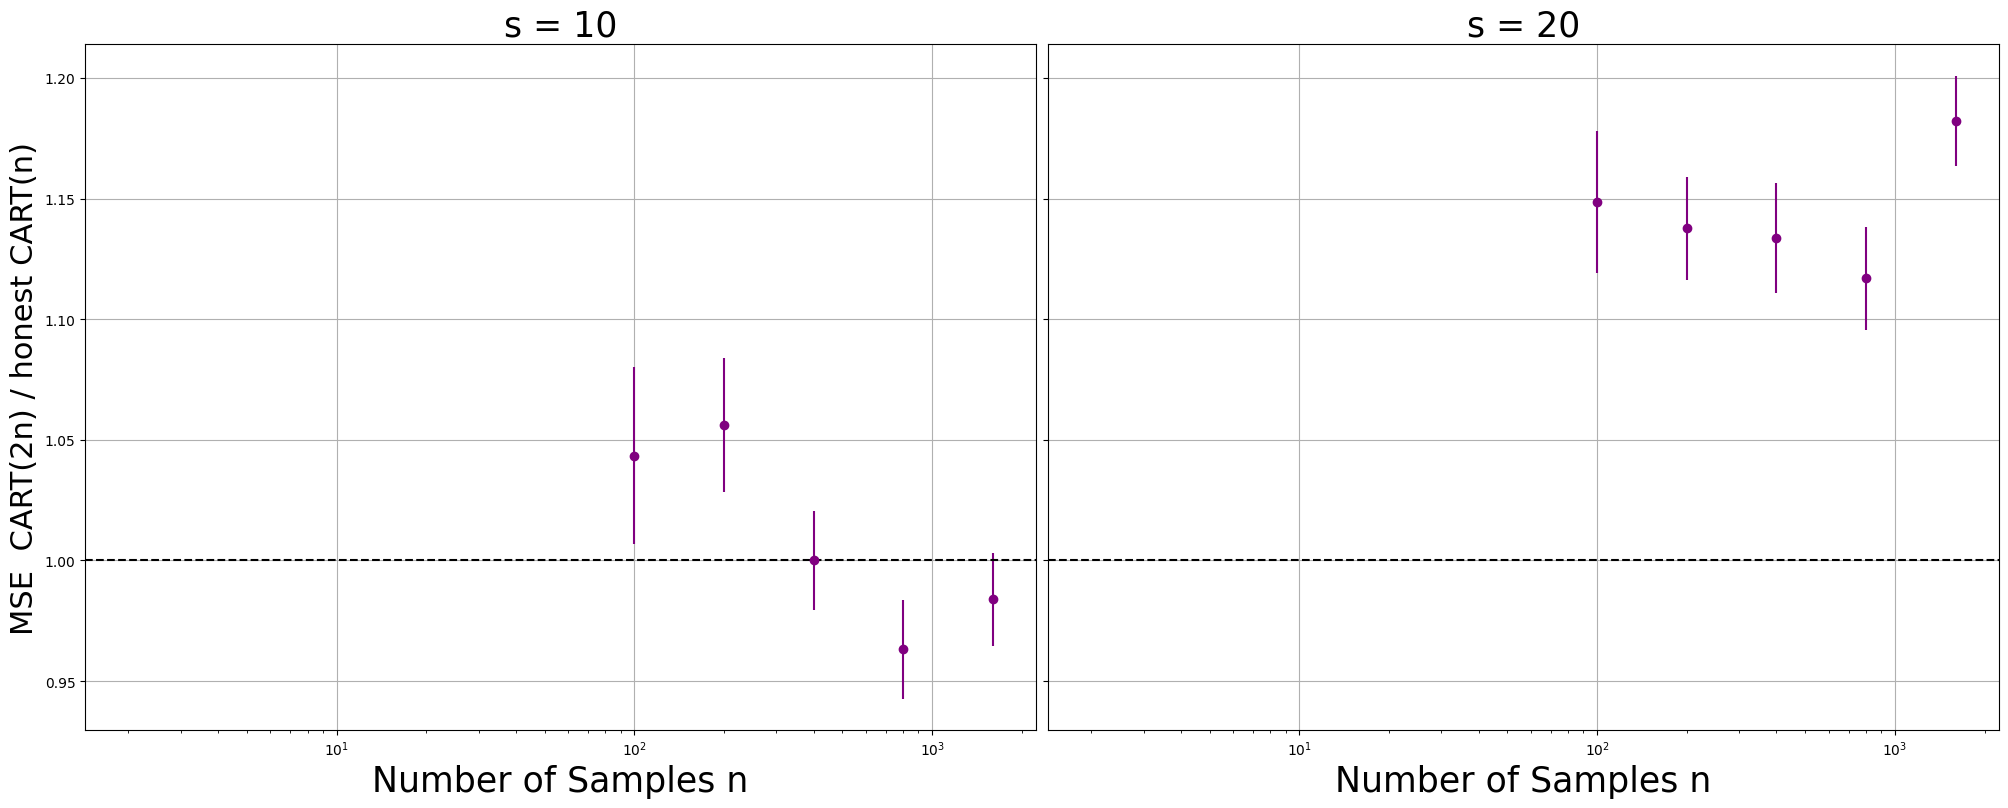

In [30]:
ratio_fig, ratio_axs = plt.subplots(1, 2, figsize=(20, 8), sharex=True, sharey=True)
for k, s in enumerate(sparsity):
    ns, rs, ses = ratios[s]
    ratio_axs[k].errorbar(ns, rs, yerr=ses, fmt='o', color='purple')
    ratio_axs[k].axhline(1.0, linestyle='dashed', color='black')
    ratio_axs[k].set_xscale('log')
    ratio_axs[k].set_xlabel('Number of Samples n', fontsize=25)
    ratio_axs[k].set_title(f's = {s}', fontsize=25)
    ratio_axs[k].grid()
ratio_axs[0].set_ylabel('MSE  CART(2n) / honest CART(n)', fontsize=22)
plt.tight_layout(pad=0.4, w_pad=0.5, h_pad=1.5)
ratio_fig.savefig('figures/linear_cts_budget_ratio.png')

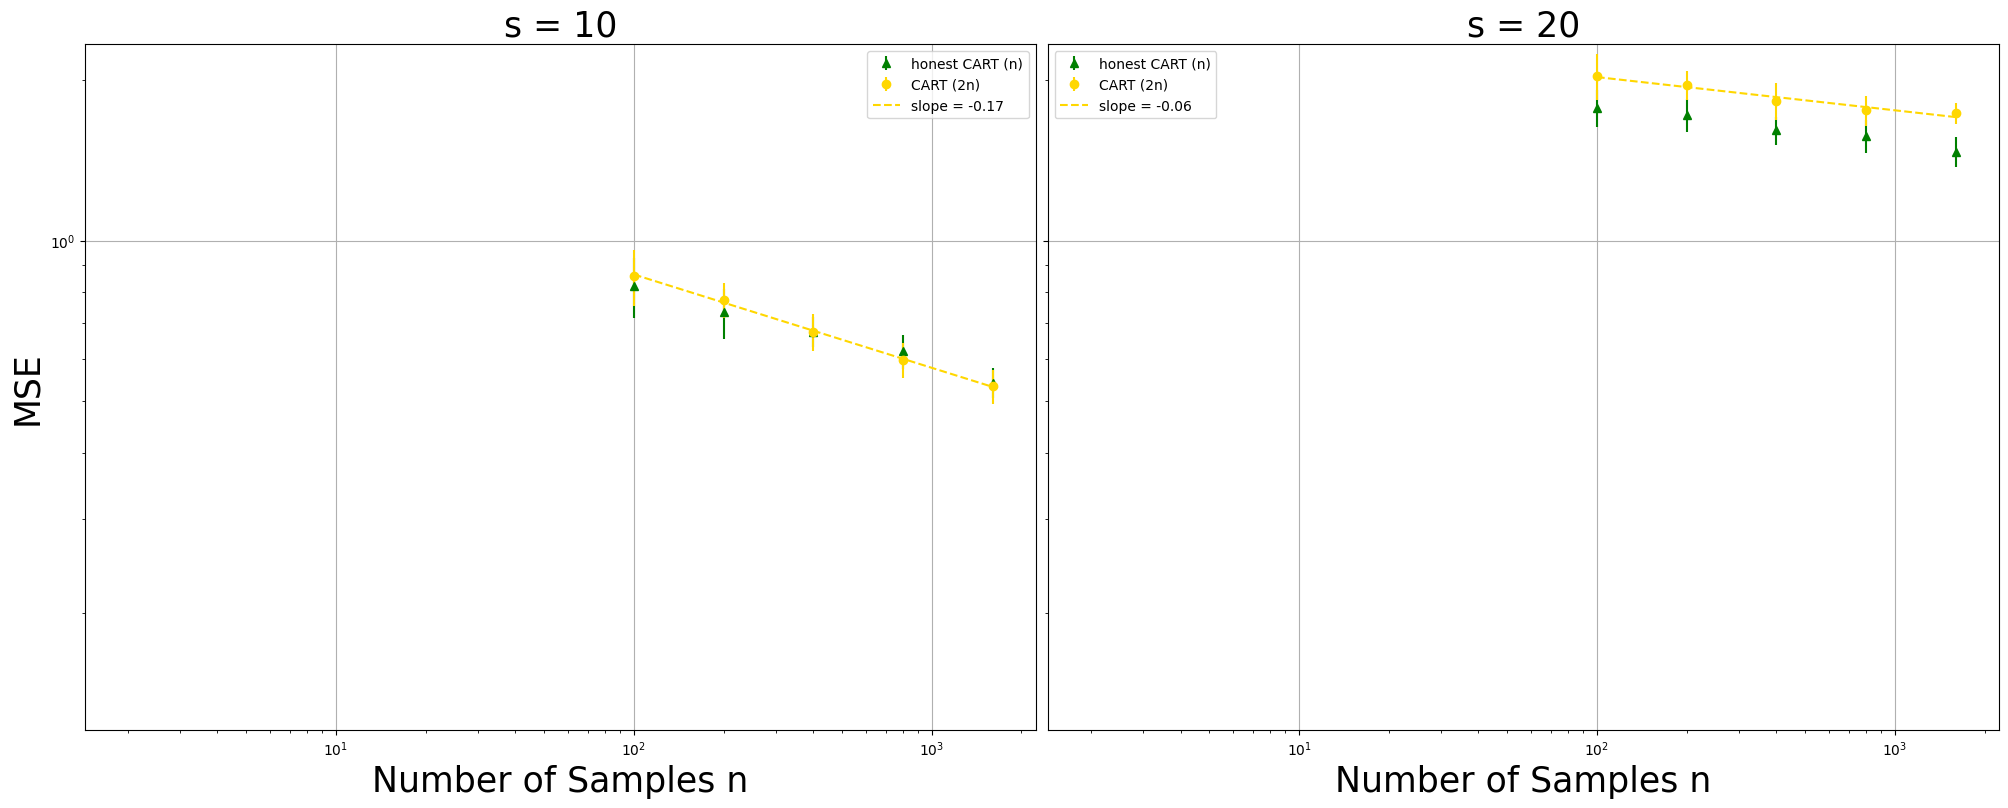

In [31]:
# Budget-matched plot: honest CART at n  vs  non-honest CART at 2n.
# CART's value at index i+1 (sample size 2n) is drawn at the x-position of honest CART at
# index i, so at any x the two series compare estimators that consumed the same 2n
# observations: honest CART uses n for the partition and a further n for the leaf averages.

n_matched = n_train[:-1]

budget_fig, budget_axs = plt.subplots(1, 2, figsize=(20, 8), sharex=True, sharey=True)
CART_2n_best_fit = []

for k, s in enumerate(sparsity):
    CART_2n     = CART_scores[k][1:]
    CART_2n_err = CART_error_bar[k][1:]
    CART_2n_best_fit.append(get_best_fit_line(log_list(n_matched), log_list(CART_2n)))

    # honest CART at n -- markers only
    budget_axs[k].errorbar(n_matched, honest_CART_scores[k][:-1], yerr = honest_CART_error_bar[k][:-1],
                           fmt = '^', label = 'honest CART (n)', color = 'green')

    # non-honest CART at 2n -- markers plus best-fit line
    budget_axs[k].errorbar(n_matched, CART_2n, yerr = CART_2n_err,
                           fmt = 'o', label = 'CART (2n)', color = 'gold')
    budget_axs[k].errorbar(n_matched,
                           pow(math.e, CART_2n_best_fit[k][0] * np.array(log_list(n_matched)) + CART_2n_best_fit[k][1]),
                           linestyle = 'dashed', label = 'slope = ' + str(CART_2n_best_fit[k][0])[:5], color = 'gold')

    # To restore the honest CART fit line, uncomment:
    # hf = get_best_fit_line(log_list(n_matched), log_list(honest_CART_scores[k][:-1]))
    # budget_axs[k].errorbar(n_matched, pow(math.e, hf[0] * np.array(log_list(n_matched)) + hf[1]),
    #                        linestyle = 'dashed', label = 'slope = ' + str(hf[0])[:5], color = 'green')

    budget_axs[k].set_xscale('log')
    budget_axs[k].set_yscale('log')
    budget_axs[k].set_xlabel('Number of Samples n', fontsize = 25)
    budget_axs[k].set_title('s = ' + str(s), fontsize = 25)
    budget_axs[k].legend(loc = 'best')
    budget_axs[k].grid()

budget_axs[0].set_ylabel('MSE', fontsize = 25)
plt.tight_layout(pad = 0.4, w_pad = 0.5, h_pad = 1.5)
budget_fig.savefig('figures/linear_cts_budget_only.png')

([<matplotlib.axis.YTick at 0x12936ddf0>,
 [])

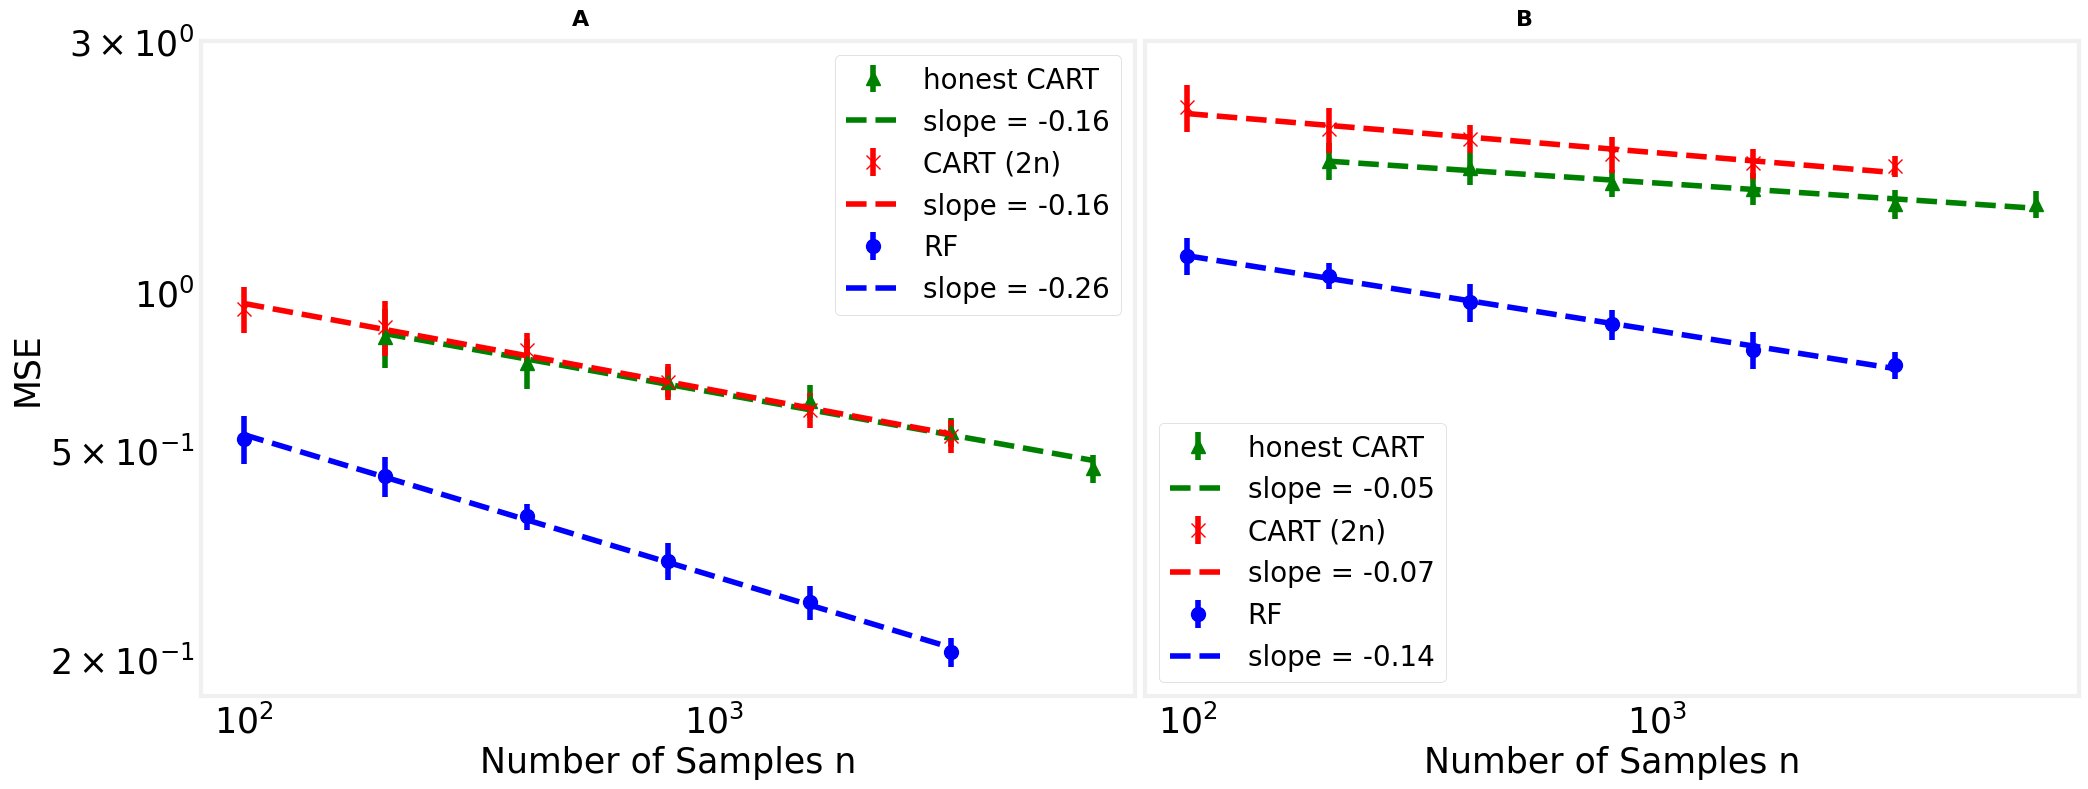

In [43]:
linear_lower_bound_fig,linear_lower_bound_axs = plt.subplots(1,2,figsize = (20,8),sharex = True,sharey = True)

# Non-honest CART consumes n observations; honest CART at n consumes 2n (n for the
# partition, n for the leaf averages). Drawing CART at n/2 therefore puts both series
# on a common budget: at any x-position, green and red have each used 2x observations.
n_half = np.array(n_train) / 2.0
n_honest = 2 * np.array(n_train)

#Plot Performance for different models
# s = 10
linear_lower_bound_axs[0].errorbar(n_honest,honest_CART_scores[0],yerr = honest_CART_error_bar[0],fmt = '^',label = 'honest CART',color = 'green')
linear_lower_bound_axs[0].errorbar(n_honest,pow(math.e,honest_CART_best_fit[0][0]*np.array(log_list(n_train))+honest_CART_best_fit[0][1]),linestyle = 'dashed',label = 'slope = ' +str(honest_CART_best_fit[0][0])[:5],color = 'green')

linear_lower_bound_axs[0].errorbar(n_train,CART_scores[0],yerr = CART_error_bar[0],fmt = 'x',label = 'CART (2n)',color = 'red')
linear_lower_bound_axs[0].errorbar(n_train,pow(math.e,CART_best_fit[0][0]*np.array(log_list(n_train))+CART_best_fit[0][1]),linestyle = 'dashed',label = 'slope = ' + str(CART_best_fit[0][0])[:5],color = 'red')

linear_lower_bound_axs[0].errorbar(n_train,RF_scores[0],yerr = RF_error_bar[0],fmt = 'o',label = 'RF',color = 'blue')
linear_lower_bound_axs[0].errorbar(n_train,pow(math.e,RF_best_fit[0][0]*np.array(log_list(n_train))+RF_best_fit[0][1]),linestyle = 'dashed',label = 'slope = ' + str(RF_best_fit[0][0])[:5],color = 'blue')

# s = 20
linear_lower_bound_axs[1].errorbar(n_honest,honest_CART_scores[1],yerr = honest_CART_error_bar[1],fmt = '^',label = 'honest CART',color = 'green')
linear_lower_bound_axs[1].errorbar(n_honest,pow(math.e,honest_CART_best_fit[1][0]*np.array(log_list(n_train))+honest_CART_best_fit[1][1]),linestyle = 'dashed',label = 'slope = ' +str(honest_CART_best_fit[1][0])[:5],color = 'green')

linear_lower_bound_axs[1].errorbar(n_train,CART_scores[1],yerr = CART_error_bar[1],fmt = 'x',label = 'CART (2n)',color = 'red')
linear_lower_bound_axs[1].errorbar(n_train,pow(math.e,CART_best_fit[1][0]*np.array(log_list(n_train))+CART_best_fit[1][1]),linestyle = 'dashed',label = 'slope = ' + str(CART_best_fit[1][0])[:5],color = 'red')

linear_lower_bound_axs[1].errorbar(n_train,RF_scores[1],yerr = RF_error_bar[1],fmt = 'o',label = 'RF',color = 'blue')
linear_lower_bound_axs[1].errorbar(n_train,pow(math.e,RF_best_fit[1][0]*np.array(log_list(n_train))+RF_best_fit[1][1]),linestyle = 'dashed',label = 'slope = ' +str(RF_best_fit[1][0])[:5],color = 'blue')

linear_lower_bound_axs[0].legend(loc = 'best')
linear_lower_bound_axs[1].legend(loc = 'best')

linear_lower_bound_axs[0].text(500.0, 3.45, 'A', fontsize=16, fontweight='bold', va='top')
linear_lower_bound_axs[1].text(500.0, 3.45, 'B', fontsize=16, fontweight='bold', va='top')
linear_lower_bound_axs[0].set_ylabel('MSE',fontsize = 25)

linear_lower_bound_axs[0].set_xlabel('Number of Samples n',fontsize = 25)
linear_lower_bound_axs[1].set_xlabel('Number of Samples n',fontsize = 25)

linear_lower_bound_axs[0].set_yscale('log')
linear_lower_bound_axs[1].set_yscale('log')
linear_lower_bound_axs[0].set_xscale('log')
linear_lower_bound_axs[1].set_xscale('log')

linear_lower_bound_axs[0].grid()
linear_lower_bound_axs[1].grid()

plt.tight_layout(pad=0.4,w_pad=0.5, h_pad=1.5)

labels = [r'$2 \times \mathregular{10^{-1}}$', r'$5 \times \mathregular{10^{-1}}$', r'$\mathregular{10^{0}}$',r'$3 \times \mathregular{10^{0}}$']
ytick = [0.2,0.5,1.0,3.0]
plt.yticks(ytick,labels)

In [46]:
import math
for k, s in enumerate(sparsity):
    a_c   = abs(CART_best_fit[k][0])        # CART's fitted exponent
    shift = a_c * math.log(2)               # constant log-drop from doubling CART's data
    for i, n in enumerate(n_train):
        gap_naive = CART_scores[k][i] / honest_CART_scores[k][i]
        gap_corr  = gap_naive * math.exp(-shift)
        frac      = shift / math.log(gap_naive)
        print(f"s={s:>3}  n={n:>5}   same-n {gap_naive:5.2f}x   "
              f"corrected {gap_corr:5.2f}x   explained {100*frac:4.0f}%")

s= 10  n=  100   same-n  1.13x   corrected  1.01x   explained   94%
s= 10  n=  200   same-n  1.17x   corrected  1.04x   explained   73%
s= 10  n=  400   same-n  1.15x   corrected  1.02x   explained   83%
s= 10  n=  800   same-n  1.09x   corrected  0.97x   explained  136%
s= 10  n= 1600   same-n  1.10x   corrected  0.98x   explained  116%
s= 10  n= 3200   same-n  1.15x   corrected  1.03x   explained   80%
s= 20  n=  100   same-n  1.26x   corrected  1.20x   explained   22%
s= 20  n=  200   same-n  1.19x   corrected  1.13x   explained   30%
s= 20  n=  400   same-n  1.22x   corrected  1.15x   explained   27%
s= 20  n=  800   same-n  1.16x   corrected  1.10x   explained   35%
s= 20  n= 1600   same-n  1.20x   corrected  1.14x   explained   29%
s= 20  n= 3200   same-n  1.18x   corrected  1.12x   explained   31%
